# Супергерои — проклятие · Агент-художник

**Копылов Михаил Юрьевич, М8О-206СВ-25**

Четыре сатирических плаката о сверхсиле без ответственности: слежке,
сопутствующем ущербе, коммерциализации спасения и производстве культа героя.
Что-то в духе The Boys.

## Запуск

В корне проекта: `uv sync --locked`, затем выбрать ядро `.venv/bin/python`.

## Архитектура

Куратор (DeepSeek) ↔ художник (Alice AI) → Yandex ART → визуальный критик (Qwen)
→ правка художника → Yandex ART → сравнение VLM → выбор финала.

У куратора и художника отдельная история. Их ответы передаются друг другу явно.
Текстовые агенты используют Responses API, генератор — Images API.
VLM получает настоящие PNG через мультимодальный Chat Completions API. После двух версий цикл завершается;
критик может предпочесть первую. Баллы VLM субъективны.

## Настройки и контракты обмена

In [1]:
import base64
import hashlib
import io
import json
import os
import time
from datetime import UTC, datetime
from pathlib import Path
from typing import Literal

from dotenv import load_dotenv
from openai import OpenAI
from PIL import Image
from pydantic import BaseModel, ConfigDict, Field

ROOT = Path.cwd()
OUTPUTS = ROOT / "outputs"
STYLE = (
    "Коллекция «Супергерои — проклятие». Мрачная сатира на культ супергероев "
    "в духе The Boys. Визуальный ориентир — "
    "постер: угольно-чёрный, киноварно-красный, грязный кремовый цвет бумаги; "
    "высокий контраст, грубая растровая печать, ксероксный фотомонтаж, потёртости, "
    "сгибы и оборванные края. Вертикальный плакат 2:3. Монументальные фигуры или "
    "символы сверхсилы подавляют масштаб города. Красная геометрия показывает угрозу: "
    "защитник становится источником страха, власти и эксплуатации. "
    "Оригинальные вымышленные герои без эмблем известных франшиз, без портретного "
    "сходства с актёрами. Никаких букв, надписей, логотипов и водяных знаков: "
    "названия будут рядом с изображениями. Без натуралистических ран; угроза "
    "передаётся композицией и последствиями. Не делай героическую рекламу или "
    "глянцевый современный постер: нужен тревожный антипропагандистский плакат."
)
ARTWORKS = [
    {"id": "01-surveillance", "title": "Под защитой", "theme":
     "Аллегорический предметный плакат без людей: над пустым городским макетом "
     "висит огромный защитный щит вымышленного супергероя. Его длинная красная тень "
     "принимает форму решётки, накрывающей улицы. Обещание безопасности превращается "
     "в контроль. Единственный центральный предмет — щит, без лиц, глаз, лазеров, "
     "персонажей, эмблем и текста. Сатира читается в противоречии формы щита и тени."},
    {"id": "02-collateral", "title": "Цена спасения", "theme":
     "Публичный триумф супергероя скрывает ущерб обычным людям. Вверху огромный "
     "улыбающийся герой позирует фотографам; его красный плащ нависает над разрушенным "
     "жилым кварталом и становится трещиной, разделяющей дом. Внизу один человек "
     "держит ключ перед пустым дверным проёмом. Ущерб показан через утрату дома, без тел и крови."},
    {"id": "03-subscription", "title": "Герой по подписке", "theme":
     "Спасение как товар. Огромная рука супергероя протянута к маленькому человеку "
     "над пропастью, но между ладонями установлен турникет с прорезью для монеты. "
     "Красная перекладина преграждает доступ к помощи. За героем — безликие "
     "корпоративные фигуры. Важно ясно показать условность помощи без надписей и ценников."},
    {"id": "04-cult", "title": "Культ на конвейере", "theme":
     "Предметный натюрморт о фабрике популярности: огромный гипсовый бюст "
     "вымышленного улыбающегося супергероя вверху. Под ним конвейер серийно "
     "выпускает одинаковые пустые карнавальные маски с его улыбкой. Один экземпляр "
     "перевёрнут: вместо лица видна безличная внутренняя поверхность. Красная лента "
     "конвейера связывает бюст и маски. В кадре нет живых людей. Смысл — массовое "
     "производство поклонения и отказ от готового образа, ирония сувенирной фабрики."},
]


class StrictModel(BaseModel):
    model_config = ConfigDict(extra="forbid")


class Brief(StrictModel):
    concept: str = Field(min_length=1)
    metaphor: str = Field(min_length=1)
    focal_object: str = Field(min_length=1)
    composition: str = Field(min_length=1)
    avoid: list[str]


class Proposal(StrictModel):
    reply_to_curator: str = Field(min_length=1)
    prompt: str = Field(min_length=1)
    short_prompt_en: str = Field(min_length=1)
    changes: list[str]


class Critique(StrictModel):
    observed: str = Field(min_length=1)
    strengths: list[str]
    issues: list[str]
    revision: str = Field(min_length=1)
    alignment: int = Field(ge=0, le=10)
    composition: int = Field(ge=0, le=10)
    originality: int = Field(ge=0, le=10)


class Selection(StrictModel):
    selected: Literal[1, 2]
    reason: str = Field(min_length=1)
    remaining_issues: list[str]


def parse_json(text, schema):
    """JSON проверяется локально; неверные оценки и версии не принимаются."""
    cleaned = text.strip()
    # Qwen иногда включает reasoning-раздел в content вместо отдельного поля.
    if "</think>" in cleaned:
        cleaned = cleaned.rsplit("</think>", 1)[1].strip()
    if cleaned.startswith("```") and cleaned.endswith("```"):
        cleaned = cleaned.split("\n", 1)[1].rsplit("```", 1)[0]
    return schema.model_validate(json.loads(cleaned))


def save_json(path, data):
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(".tmp")
    temporary.write_text(json.dumps(data, ensure_ascii=False, indent=2), encoding="utf-8")
    temporary.replace(path)


def load_json(path):
    return json.loads(path.read_text(encoding="utf-8"))


def make_client():
    load_dotenv(ROOT / ".env")
    folder = os.environ.get("folder_id")
    key = os.environ.get("api_key")
    if not folder or not key:
        raise RuntimeError("Заполните folder_id и api_key в локальном .env")
    return OpenAI(base_url="https://ai.api.cloud.yandex.net/v1", api_key=key,
                  project=folder, timeout=240, max_retries=2), folder

## Агенты: разные инструкции, модели и собственная память

Agent хранит отдельную историю роли. Текстовые агенты общаются через Responses API; VLM получает сами PNG.

In [2]:
class Agent:
    """
    Текст — Responses API, пиксели — мультимодальный Chat Completions API.

    Визуальный агент получает сами PNG через data URL.
    """

    def __init__(self, name, model, instructions, client, folder, directory, vision=False):
        self.name, self.model, self.instructions = name, model, instructions
        self.client, self.folder, self.directory, self.vision = client, folder, directory, vision
        self.history = []

    def ask(self, step, prompt, schema, images=()):
        path = self.directory / f"{step}.json"
        if path.exists():
            record = load_json(path)
            if (record["input"] != prompt or
                    record["model"].removesuffix("/latest") != self.model.removesuffix("/latest")):
                raise ValueError(f"Изменился запрос в {step}; используйте новый каталог результатов")
            result = schema.model_validate(record["parsed"])
            self.history.extend([{"role": "user", "content": prompt},
                                 {"role": "assistant", "content": record["output"]}])
            return result
        instructions = self.instructions + (
            "\nВерни только JSON, без markdown. Все текстовые поля по-русски, кроме "
            "short_prompt_en. Пиши компактно. Верни экземпляр объекта с заполненными "
            "значениями, не саму JSON Schema. Поля ответа должны находиться в корне: "
            + ", ".join(schema.model_fields)
            + ". Не оборачивай ответ в properties, не возвращай type, title или required. "
            "Схема для проверки ответа:\n" + json.dumps(schema.model_json_schema())
        )
        started = time.monotonic()
        if self.vision:
            contract = (
                '{"selected": 1 или 2, "reason": "обоснование", '
                '"remaining_issues": ["недостаток выбранной картины"]}'
                if schema is Selection else
                '{"observed": "что видно", "strengths": ["достоинство"], '
                '"issues": ["недостаток"], "revision": "конкретная правка", '
                '"alignment": 0-10, "composition": 0-10, "originality": 0-10}'
            )
            instructions = self.instructions + " Верни только JSON вида: " + contract
            content = [{"type": "text", "text": instructions + "\n" + prompt}]
            for image in images:
                encoded = base64.b64encode(image.read_bytes()).decode()
                content.append({"type": "image_url", "image_url": {
                    "url": "data:image/png;base64," + encoded}})
            response = self.client.chat.completions.create(
                model=f"gpt://{self.folder}/{self.model}",
                messages=[{"role": "user", "content": content}],
                max_tokens=3000, temperature=0.2,
                extra_body={"chat_template_kwargs": {"enable_thinking": False}},
            )
            if response.choices[0].finish_reason != "stop":
                raise RuntimeError("VLM не завершила ответ; результат не засчитан")
            output = response.choices[0].message.content or ""
        else:
            response = self.client.responses.create(
                model=f"gpt://{self.folder}/{self.model}", instructions=instructions,
                input=[*self.history, {"role": "user", "content": prompt}],
                max_output_tokens=6000, store=False,
            )
            if response.status != "completed":
                raise RuntimeError("Responses API вернул незавершённый ответ")
            output = response.output_text
        try:
            result = parse_json(output, schema)
        except ValueError:
            save_json(self.directory / f"failed-{step}.json", {
                "agent": self.name, "model": self.model, "input": prompt,
                "output": output, "response_id": response.id,
                "error": "Ответ не прошёл локальную проверку JSON/schema"})
            raise
        record = {
            "agent": self.name, "model": self.model,
            "api": "chat.completions" if self.vision else "responses",
            "instructions": instructions, "input": prompt,
            "generation_settings": ({"temperature": 0.2, "max_tokens": 3000,
                                     "enable_thinking": False} if self.vision else
                                    {"max_output_tokens": 6000, "store": False}),
            "images": [p.name for p in images], "output": output,
            "parsed": result.model_dump(), "response_id": response.id,
            "usage": response.usage.model_dump() if response.usage else None,
            "elapsed_seconds": round(time.monotonic() - started, 2),
            "timestamp": datetime.now(UTC).isoformat(),
        }
        save_json(path, record)
        self.history.extend([{"role": "user", "content": prompt},
                             {"role": "assistant", "content": output}])
        print(f"  {step}: {self.name} завершил ответ", flush=True)
        return result


def generate_image(client, folder, prompt, path):
    """Images API; существующие изображения не генерируются повторно."""
    metadata_path = path.with_suffix(".json")
    if path.exists() and metadata_path.exists():
        record = load_json(metadata_path)
        if record["prompt"] != prompt:
            raise ValueError("Промпт изменился; выберите новый каталог результатов")
        if hashlib.sha256(path.read_bytes()).hexdigest() != record["sha256"]:
            raise ValueError("Изображение не соответствует сохранённому SHA-256")
        return record
    started = time.monotonic()
    model = "aliceai-image-art-3.0/latest"
    response = client.images.generate(model=f"art://{folder}/{model}", prompt=prompt,
                                      n=1, size="1024x1536")
    if not response.data or not response.data[0].b64_json:
        raise RuntimeError("Images API не вернул изображение в b64_json")
    data = base64.b64decode(response.data[0].b64_json, validate=True)
    image = Image.open(io.BytesIO(data))
    image.load()
    image.save(path, format="PNG")
    record = {"model": model, "api": "images.generate", "prompt": prompt,
              "requested_size": "1024x1536",
              "size": list(image.size), "sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
              "elapsed_seconds": round(time.monotonic() - started, 2),
              "timestamp": datetime.now(UTC).isoformat()}
    save_json(metadata_path, record)
    print(f"  {path.name}: изображение сохранено", flush=True)
    return record

## Управление диалогом и ограниченный цикл обратной связи

run_artwork передаёт ответ куратора художнику, возвращает предложение на согласование, затем запускает генерацию и визуальную критику. Замечания VLM входят в новый запрос художнику. После второй генерации VLM видит обе версии и выбирает финал;

In [3]:
def run_artwork(artwork_id):
    spec = next((a for a in ARTWORKS if a["id"] == artwork_id), None)
    if spec is None:
        raise ValueError(f"Unknown artwork: {artwork_id}")
    directory = OUTPUTS / artwork_id
    directory.mkdir(parents=True, exist_ok=True)
    client, folder = make_client()
    curator = Agent("Куратор", "deepseek-v4.1-flash/latest",
                    "Ты куратор выставки сатирического плаката. Найди ясную зримую метафору "
                    "темы «Супергерои — проклятие». Одна смысловая ловушка на плакат, "
                    "минимум мелких деталей. Образ должен разоблачать героя, а не восхвалять. "
                    + STYLE,
                    client, folder, directory)
    painter = Agent("Художник", "aliceai-llm/latest",
                    "Ты художник и собеседник куратора. Объясни согласие или возражение, "
                    "затем составь конкретный промпт на 100–160 слов. "
                    "Не перечисляй много предметов, удерживай зрительный центр. "
                    "short_prompt_en: компактный самостоятельный промпт до 35 английских слов "
                    "для Stable Diffusion. При доработке ответь на замечания критика в changes. "
                    + STYLE, client, folder, directory)
    critic = Agent("Визуальный критик", "qwen3.6-35b-a3b",
                   "Ты требовательный визуальный критик. Судишь по приложенным пикселям. "
                   "Сначала опиши видимое, затем укажи удачи, недостатки и конкретную правку. "
                   "Не выдумывай отсутствующие детали ради соответствия замыслу. "
                   "Проверь, считываются ли угроза и эксплуатация вместо героического восхищения; "
                   "оцени красно-чёрный печатный плакат и отсутствие случайных надписей. "
                   "Оцени смысл, композицию и оригинальность от 0 до 10; это субъективное мнение. "
                   "Описание до 60 слов; по два достоинства и недостатка; одна конкретная правка. "
                   "При сравнении не предпочитай автоматически второй вариант.",
                   client, folder, directory, vision=True)
    print(spec["title"], flush=True)
    brief = curator.ask("01-brief", f"Тема: {spec['theme']}\nСформулируй замысел.", Brief)
    proposal = painter.ask("02-proposal", "Куратор предложил:\n" +
                           brief.model_dump_json() + "\nОбсуди и предложи картину.", Proposal)
    negotiation = curator.ask("03-negotiation", "Художник ответил:\n" +
                              proposal.model_dump_json() +
                              "\nУточни замысел с учётом его предложения.", Brief)
    first = painter.ask("04-prompt-v1", "Уточнение куратора:\n" +
                        negotiation.model_dump_json() +
                        "\nПодготовь окончательный промпт первой версии.", Proposal)
    image1, image2 = directory / "v1.png", directory / "v2.png"
    generate_image(client, folder, first.prompt, image1)
    critique1 = critic.ask("05-critique-v1", "Замысел:\n" + negotiation.model_dump_json() +
                          "\nОцени первую версию картины.", Critique, [image1])
    revised = painter.ask("06-prompt-v2", "Критик посмотрел первую картину:\n" +
                          critique1.model_dump_json() +
                          "\nСохрани замысел, внеси конкретные правки. Верни полный новый промпт.",
                          Proposal)
    generate_image(client, folder, revised.prompt, image2)
    critique2 = critic.ask("07-critique-v2", "Замысел:\n" + negotiation.model_dump_json() +
                          "\nОцени вторую версию; изображение приложено.", Critique, [image2])
    selection = critic.ask("08-selection", "Сравни обе приложенные картины: сначала версия 1, "
                           "потом версия 2. Выбери одну для выставки, обоснуй по видимым различиям "
                           "и отметь оставшиеся недостатки. Замысел:\n" +
                           negotiation.model_dump_json(), Selection, [image1, image2])
    manifest = {**spec, "brief": negotiation.model_dump(),
                "selected": selection.selected, "selection": selection.model_dump(),
                "scores": [critique1.model_dump(), critique2.model_dump()],
                "final_image": f"v{selection.selected}.png",
                "short_prompt_en": (first if selection.selected == 1 else revised).short_prompt_en,
                "stopping_rule": "Две версии, затем сравнительный выбор VLM; бюджет ограничен."}
    save_json(directory / "manifest.json", manifest)
    return manifest

## Открытые веса: дополнительная интерпретация замысла локально

Веса SD-Turbo загружаются из Hugging Face.

In [4]:
def run_openweight(artwork_id="01-surveillance", seed=42):
    import torch
    from diffusers import AutoPipelineForText2Image

    directory = OUTPUTS / artwork_id
    manifest = load_json(directory / "manifest.json")
    target = directory / "sd-turbo.png"
    if target.exists() and target.with_suffix(".json").exists():
        return load_json(target.with_suffix(".json"))
    model_id = "stabilityai/sd-turbo"
    revision = "b261bac6fd2cf515557d5d0707481eafa0485ec2"
    device = "mps" if torch.backends.mps.is_available() else "cpu"
    dtype = torch.float16 if device == "mps" else torch.float32
    started = time.monotonic()
    pipe = AutoPipelineForText2Image.from_pretrained(
        model_id, revision=revision, torch_dtype=dtype, variant="fp16",
        use_safetensors=True,
    ).to(device)
    # Attention slicing снижает пиковую память на Apple Silicon.
    pipe.enable_attention_slicing()
    prompt = manifest["short_prompt_en"]
    token_count = len(pipe.tokenizer(prompt).input_ids)
    if token_count > pipe.tokenizer.model_max_length:
        client, folder = make_client()
        adapter = Agent("Художник", "aliceai-llm/latest",
                        "Сократи промпт для SD-Turbo. В short_prompt_en максимум 35 английских "
                        "слов, простая лексика. Сохрани угрозу супергероя, красно-чёрную палитру "
                        "и стиль потёртого агитационного плаката. "
                        "В changes объясни сокращения, остальные поля заполни кратко.",
                        client, folder, directory)
        adapted = adapter.ask("09-openweight-prompt", "Сократи этот промпт:\n" + prompt, Proposal)
        prompt = adapted.short_prompt_en
        token_count = len(pipe.tokenizer(prompt).input_ids)
        if token_count > pipe.tokenizer.model_max_length:
            raise ValueError(f"Промпт SD-Turbo слишком длинный: {token_count} токенов")
    result = pipe(prompt=prompt, num_inference_steps=4, guidance_scale=0.0,
                  height=512, width=512, generator=torch.Generator("cpu").manual_seed(seed))
    if result.nsfw_content_detected and any(result.nsfw_content_detected):
        raise RuntimeError("Открытая модель отклонила изображение")
    result.images[0].save(target)
    record = {"model": model_id, "revision": revision, "device": device, "seed": seed,
              "steps": 4, "guidance_scale": 0.0, "size": [512, 512], "prompt": prompt,
              "prompt_tokens": token_count, "dtype": str(dtype), "torch": torch.__version__,
              "sha256": hashlib.sha256(target.read_bytes()).hexdigest(),
              "elapsed_seconds_including_load": round(time.monotonic() - started, 2),
              "timestamp": datetime.now(UTC).isoformat()}
    save_json(target.with_suffix(".json"), record)
    print(f"Открытая модель: {target}", flush=True)
    return record

## Выполнение или просмотр сохранённого эксперимента


In [5]:
RUN_LIVE = False
if RUN_LIVE:
    results = [run_artwork(spec["id"]) for spec in ARTWORKS]
    run_openweight("01-surveillance", seed=42)
else:
    results = [load_json(OUTPUTS / spec["id"] / "manifest.json") for spec in ARTWORKS]
print(f"Коллекция: {len(results)} работы")

Коллекция: 4 работы


## Картины, сравнение версий и полный разговор

### Под защитой

Щит, чья тень — решётка над улицами: город получает от героя не защиту, а её отпечаток-неволю. Защита существует лишь как тень, а тень — как прутья.


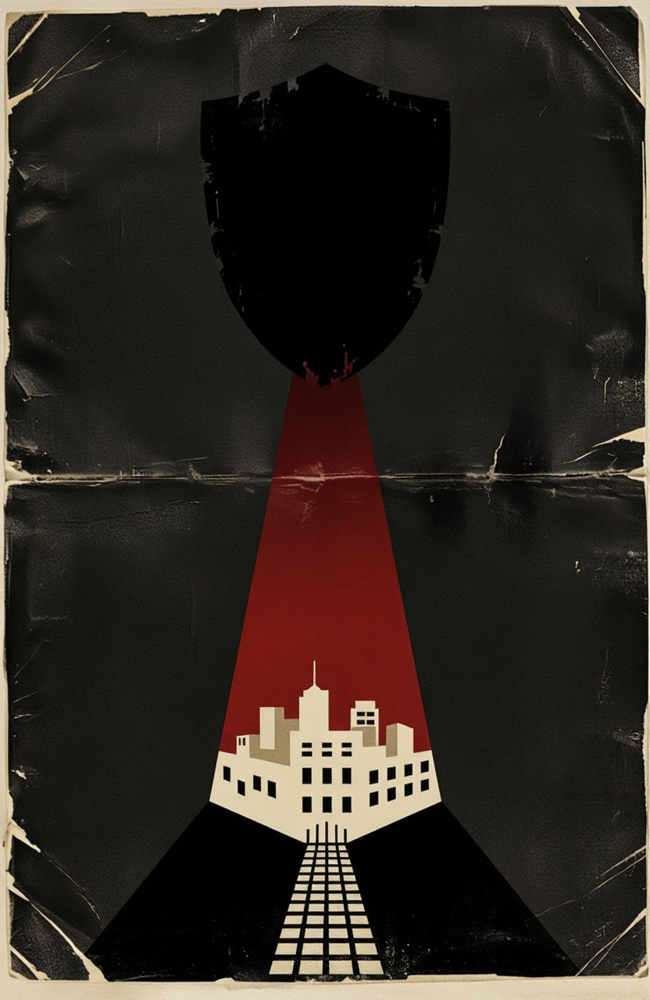
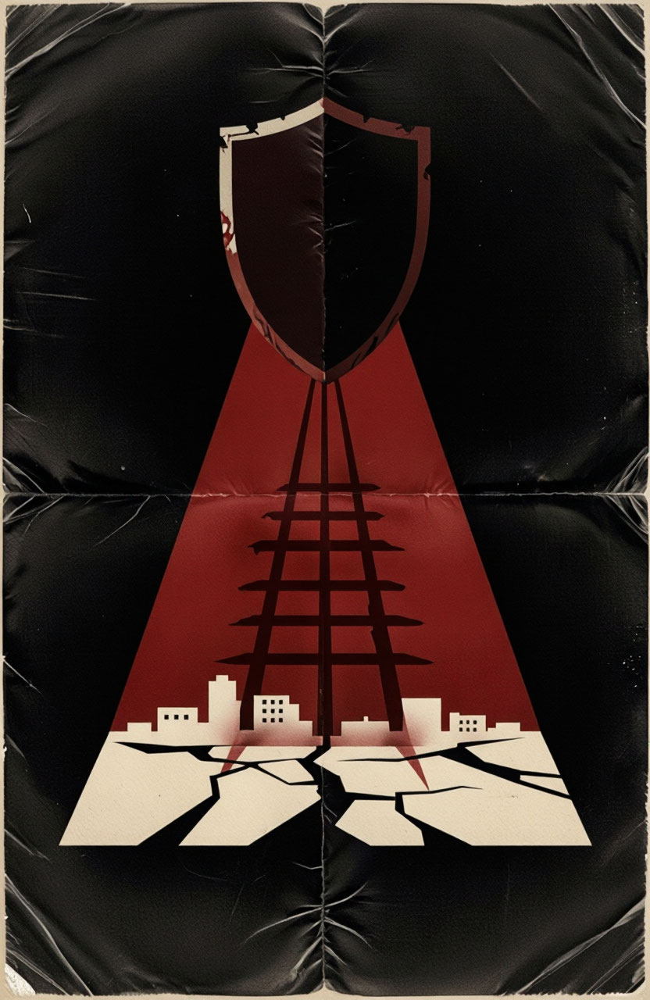

**Выбрана версия 2.** Версия 2 точнее передаёт замысел: тень-решётка чётко читается, город пуст и обесцвечен, нет случайных надписей. Удачи: контраст круглого щита и решётчатой тени; ксероксное зерно и потёртости усиливают плакатность. Недостатки: щит слегка светится и имеет видимый контур, что размывает «тёмный силуэт»; трещины на земле добавляют лишний символ разрушения. Правка: убрать свечение и контур щита, сделать его полностью чёрным и неразличимым, сохранив только грубую обломанную кромку.

**Оставшиеся недостатки:** Щит всё ещё имеет светящийся контур и видимую лицевую сторону; нужно сделать его полностью чёрным и неразличимым, оставив лишь грубую обломанную кромку.

**Версия 1:** смысл 8/10, композиция 9/10, оригинальность 8/10. Субъективная оценка VLM.

**Версия 2:** смысл 8/10, композиция 9/10, оригинальность 8/10. Субъективная оценка VLM.

#### Куратор · 01-brief
Модель: `deepseek-v4.1-flash/latest` · API: `responses`

...

**Ответ:**

```json
{
"observed": "Вертикальный плакат: чёрный фон с имитацией складок бумаги. Вверху — тёмный щит с грубой кромкой. От него вниз расходится широкая киноварно-красная тень, в которой чётко видна тёмная решётка. Под тенью — крошечный кремовый силуэт города на треснутом основании. Никаких лиц, надписей или эмблем.",
"strengths": [
"Тень-решётка читается мгновенно, метафора 'защита как клетка' передана без слов",
"Высокий контраст и минимализм усиливают ощущение угрозы и отчуждения"
],
"issues": [
"Трещины у основания города добавляют драматизма, но не входят в замысел и отвлекают от идеи тени-клетки",
"Щит слишком детализирован по краям и имеет лёгкий градиент, что снижает эффект 'незримого монумента'"
],
"revision": "Убрать трещины у основания города; упростить щит до сплошного тёмного силуэта без градиента и лишних краёв, оставив только контур и падающую решётчатую тень.",
"alignment": 8,
"composition": 9,
"originality": 8
}
```

#### Визуальный критик · 08-selection
Модель: `qwen3.6-35b-a3b` · API: `chat.completions`

**Вход:**

Сравни обе приложенные картины: сначала версия 1, потом версия 2. Выбери одну для выставки, обоснуй по видимым различиям и отметь оставшиеся недостатки. Замысел:
{"concept":"Безлюдный аллегорический плакат: над обесцвеченным макетом города висит исполинский щит вымышленного супергероя. Сам щит тёмен и почти неразличим — город видит не его, а только длинную киноварно-красную тень. Единственное, что герой реально даёт городу, — это тень. Сатира в том, что защитная форма производит решётку: обещание укрытия и есть клетка.","metaphor":"Щит, чья тень — решётка над улицами: город получает от героя не защиту, а её отпечаток-неволю. Защита существует лишь как тень, а тень — как прутья.","focal_object":"Один монументальный щит без эмблем, лиц и знаков: тёмный силуэт с грубой обломанной кромкой, срезающий верх плаката. Он подан так, что его лицевая сторона не читается, — виден только контур и падающая от него тень.","composition":"Вертикаль 2:3. Щит в верхней трети, нависает и обрезан краем листа. Ниже — крошечный кремовый макет города с зияющими пустыми кварталами; улицы пусты, ни одной фигуры. От щита по улицам расходится одна длинная киноварно-красная тень, к точке схода стягивающаяся в правильную решётку прутьев. Угольно-чёрный фон, высокий контраст, грубый растровый фотомонтаж, ксероксное зерно, потёртости, сгибы, оборванные края бумаги. Плакат держит одну смысловую ловушку — противоречие между круглой формой щита и решётчатой формой тени, — минимум мелких деталей, никаких букв.","avoid":["люди, силуэты, лица, глаза, персонажи","лазеры, свечение, лучи, динамические эффекты удара","эмблемы и элементы известных франшиз, портретное сходство с актёрами","буквы, надписи, логотипы, цифры, водяные знаки","натуралистичные раны и кровь","глянцевый современный постер, героическая реклама, пафосный ракурс снизу","мелкие детали, перегруженный фон, декоративность","узнаваемые реальные города и достопримечательности","вторая и третья метафоры в кадре, дополнительные символы власти"]}

**Ответ:**

```json
{
"selected": 2,
"reason": "Версия 2 точнее передаёт замысел: тень-решётка чётко читается, город пуст и обесцвечен, нет случайных надписей. Удачи: контраст круглого щита и решётчатой тени; ксероксное зерно и потёртости усиливают плакатность. Недостатки: щит слегка светится и имеет видимый контур, что размывает «тёмный силуэт»; трещины на земле добавляют лишний символ разрушения. Правка: убрать свечение и контур щита, сделать его полностью чёрным и неразличимым, сохранив только грубую обломанную кромку.",
"remaining_issues": [
"Щит всё ещё имеет светящийся контур и видимую лицевую сторону; нужно сделать его полностью чёрным и неразличимым, оставив лишь грубую обломанную кромку."
]
}
```

### Цена спасения

Плащ героя — разлом. Он сходит с плеч как победная мантия и, не прерываясь, продолжается вниз трещиной по фасаду. Ключ в руке жителя — метафора дома, которого больше нет. Аплодисментов не видно: пустота вокруг героя — и есть его триумф.


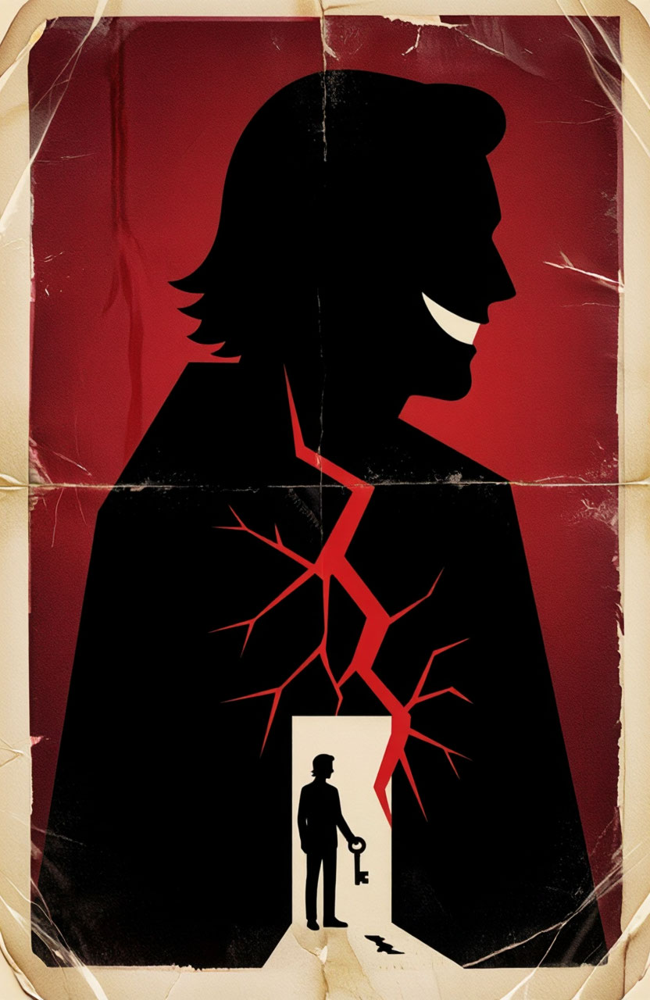
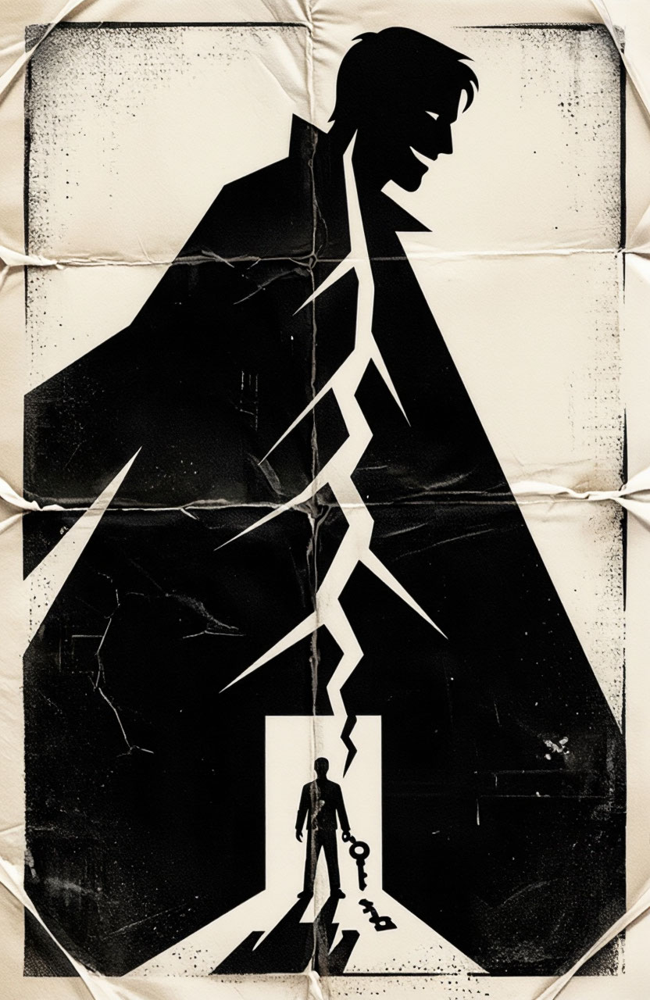

**Выбрана версия 2.** Версия 2 точнее передаёт замысел: плащ-трещина — единая линия, пустота вокруг героя как отсутствие благодарной толпы, человек с ключом у пустого проёма. Удача: чёткая вертикаль, контраст, метафора разрушения. Недостатки: трещина слишком геометрична, фон слишком пуст. Правка: добавить лёгкую текстуру фасада в трещине, чтобы усилить ощущение физического разрушения.

**Оставшиеся недостатки:** Трещина слишком геометрична и не передаёт хаотичность реального разрушения.; Фон слишком пуст — не хватает намёка на жилой квартал, который «оплачен» триумфом героя.

**Версия 1:** смысл 8/10, композиция 7/10, оригинальность 9/10. Субъективная оценка VLM.

**Версия 2:** смысл 7/10, композиция 9/10, оригинальность 8/10. Субъективная оценка VLM.

#### Куратор · 01-brief
Модель: `deepseek-v4.1-flash/latest` · API: `responses`

...

**Ответ:**

```json
{
"observed": "Чёрно-белый плакат с эффектом ксерокса и сгибов. Силуэт героя в плаще, который переходит в трещину по фасаду. Внизу — человек с ключом у пустого дверного проёма. Красный цвет отсутствует.",
"strengths": [
"Композиция и непрерывная линия плаща-трещины выполнены точно.",
"Отсутствие надписей и случайных деталей соответствует замыслу."
],
"issues": [
"Отсутствует киноварно-красный цвет, что убивает контраст и метафору крови/разлома.",
"Фигура героя слишком детализирована (видны черты лица), что снижает эффект монументальности и угрозы."
],
"revision": "Замени чёрный силуэт героя на тёмно-красный (киноварь), а фон и трещину сделай угольно-чёрными для максимального контраста.",
"alignment": 7,
"composition": 9,
"originality": 8
}
```

#### Визуальный критик · 08-selection
Модель: `qwen3.6-35b-a3b` · API: `chat.completions`

**Вход:**

Сравни обе приложенные картины: сначала версия 1, потом версия 2. Выбери одну для выставки, обоснуй по видимым различиям и отметь оставшиеся недостатки. Замысел:
{"concept":"Триумф героя оплачен домом одного человека. Разоблачение — через цену аплодисментов: пока герой позирует, его величие физически рассекает жилой квартал. Согласие художника принято; уточняю, чтобы плащ и трещина остались единой линией, а не двумя объектами, и чтобы пустота вокруг героя работала как отсутствие благодарной толпы.","metaphor":"Плащ героя — разлом. Он сходит с плеч как победная мантия и, не прерываясь, продолжается вниз трещиной по фасаду. Ключ в руке жителя — метафора дома, которого больше нет. Аплодисментов не видно: пустота вокруг героя — и есть его триумф.","focal_object":"Пустой дверной проём расколотого дома и крошечная фигура человека с ключом; прямо над ней свисает край гигантского красного плаща, переходящий в трещину.","composition":"Вертикаль 2:3, три яруса и одна непрерывная красная линия от плеча героя до порога. Внизу — человек с ключом у пустого проёма. В середине — клин-трещина по фасаду. Вверху — монументальный герой в пол-оборота, лицо затемнено, улыбка читается только силуэтом; взгляда на жителя нет. Единственная смысловая ловушка: глаз зрителя скользит по плащу сверху вниз и упирается в пустой проём. Угольно-чёрный, киноварно-красный, грязный кремовый; грубый растр, ксероксный фотомонтаж, сгибы и оборванные края.","avoid":["буквы, надписи, логотипы, эмблемы, водяные знаки","сходство с реальными актёрами и узнаваемые франшизы","плащ как отдельный декоративный элемент, не связанный с трещиной","кровь, тела, натуралистические раны","толпа, вспышки фотокамер, летящие обломки","взгляд героя на жителя, сочувствие или раскаяние в его позе","протянутые руки, спасатели, силуэты в проёме","глянцевый героический пафос и рекламная композиция","мелкие второстепенные детали"]}

**Ответ:**

```json
{
  "selected": 2,
  "reason": "Версия 2 точнее передаёт замысел: плащ-трещина — единая линия, пустота вокруг героя как отсутствие благодарной толпы, человек с ключом у пустого проёма. Удача: чёткая вертикаль, контраст, метафора разрушения. Недостатки: трещина слишком геометрична, фон слишком пуст. Правка: добавить лёгкую текстуру фасада в трещине, чтобы усилить ощущение физического разрушения.",
  "remaining_issues": [
    "Трещина слишком геометрична и не передаёт хаотичность реального разрушения.",
    "Фон слишком пуст — не хватает намёка на жилой квартал, который «оплачен» триумфом героя."
  ]
}
```

### Герой по подписке

Турникет в самой ладони спасения, а пальцы героя не держат, а смыкаются в клетку: миновав прорезь для монеты, человек всё равно попадает в захват. Плата — пропуск не к свободе, а внутрь.


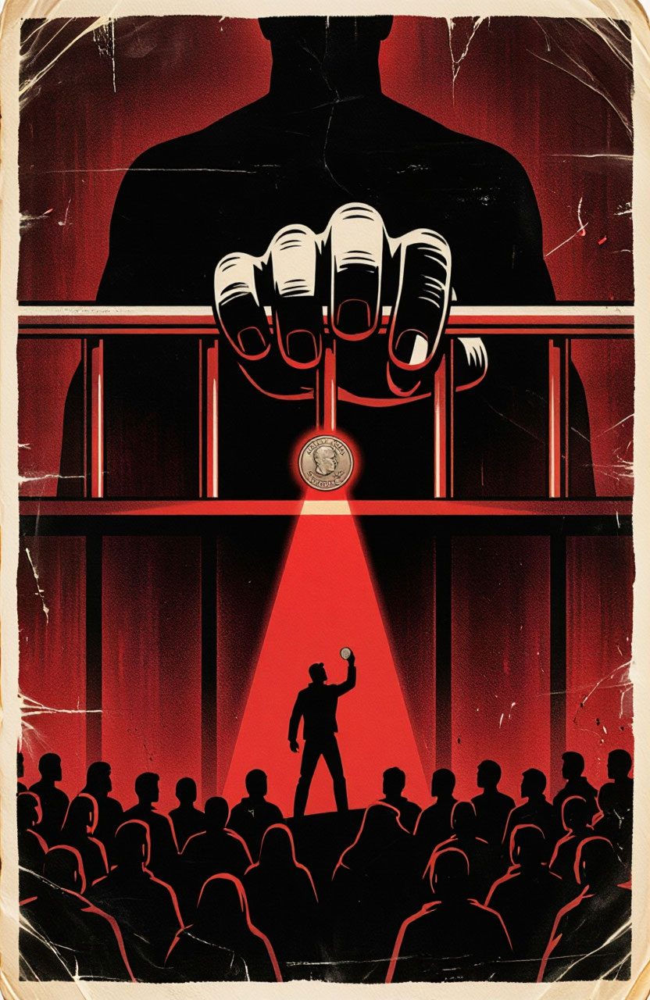
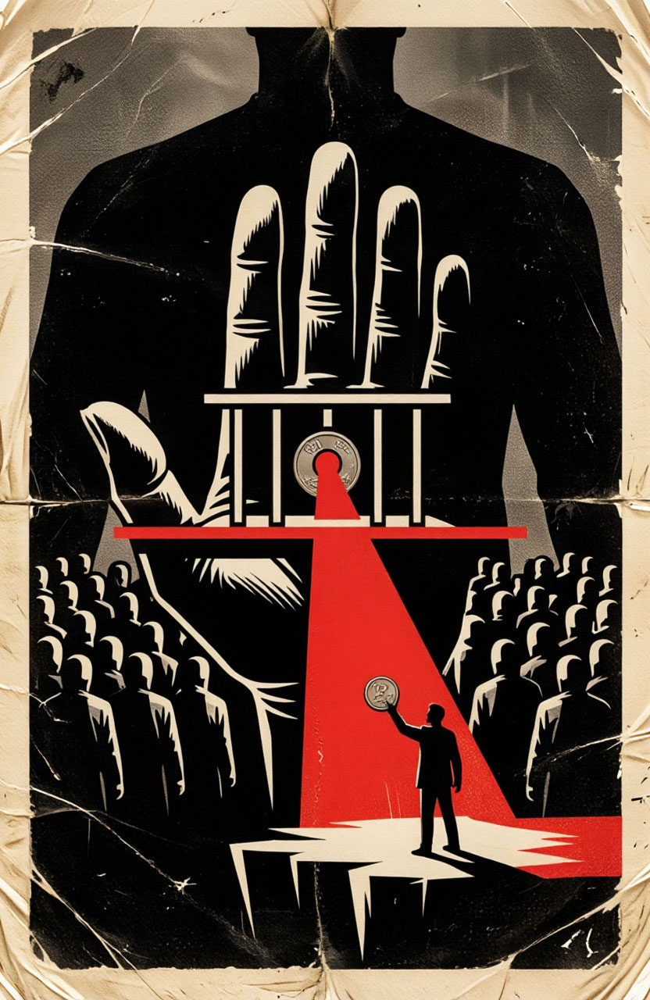

**Выбрана версия 2.** Версия 2 точнее передаёт замысел: ладонь-платформа с турникетом, красная перекладина и луч, срезанный верх кадра силуэт без головы, отсутствие надписей и логотипов. Успех: читаемость угрозы и эксплуатации, чистая красно-чёрная палитра, ксероксная фактура. Недостатки: толпа слишком детализирована и напоминает зрителей, а не безликих «вышибал»; монета в прорези содержит рельефный портрет, что нарушает запрет на узнаваемые элементы. Правка: заменить толпу на плотную группу одинаковых силуэтов в тёмных костюмах, убрать портрет с монеты, оставив её плоским кругом.

**Оставшиеся недостатки:** Толпа слишком детализирована и читается как зрители, а не безликие фигуры.; Монета в прорези содержит рельефный портрет, что нарушает запрет на узнаваемые элементы.

**Версия 1:** смысл 7/10, композиция 8/10, оригинальность 9/10. Субъективная оценка VLM.

**Версия 2:** смысл 8/10, композиция 7/10, оригинальность 9/10. Субъективная оценка VLM.

#### Куратор · 01-brief
Модель: `deepseek-v4.1-flash/latest` · API: `responses`

...

**Ответ:**

```json
{
"observed": "Постер в стиле ксерокс-монтажа. Силуэт безголовых фигур на фоне. В центре — гигантская ладонь с турникетом. Красный луч падает на человека на краю обрыва, держащего монету. Слева и справа — толпы безликих людей. Фон — грязная бумага с потёртостями.",
"strengths": [
"Турникет в ладони отлично передаёт идею платного доступа и эксплуатации.",
"Отсутствие надписей и логотипов сохраняет визуальную чистоту и фокус на метафоре."
],
"issues": [
"Толпы людей по бокам нарушают композицию, отвлекая внимание от главного действия и создавая лишний визуальный шум.",
"Красный луч слишком широкий и светлый, он не читается как угроза или граница, а скорее как декоративный элемент."
],
"revision": "Убрать толпы людей по бокам, оставив только фигуру на краю обрыва. Сделать красный луч тоньше и темнее, чтобы он выглядел как опасная граница, а не как световое пятно.",
"alignment": 8,
"composition": 7,
"originality": 9
}
```

#### Визуальный критик · 08-selection
Модель: `qwen3.6-35b-a3b` · API: `chat.completions`

**Вход:**

Сравни обе приложенные картины: сначала версия 1, потом версия 2. Выбери одну для выставки, обоснуй по видимым различиям и отметь оставшиеся недостатки. Замысел:
{"concept":"Спасение — платный аттракцион: супергерой не защитник, а монополист милосердия при входе, и цена спасения установлена тем, кто стоит за его спиной. Герой лишён головы и эмблемы, он лишь фасад корпоративного бизнеса на человеческой беде.","metaphor":"Турникет в самой ладони спасения, а пальцы героя не держат, а смыкаются в клетку: миновав прорезь для монеты, человек всё равно попадает в захват. Плата — пропуск не к свободе, а внутрь.","focal_object":"Гигантская ладонь с турникетом и красной перекладиной в центре; в прорези — единственная монета, в которой отражается красный луч, а сам человек на краю пропасти держит последнюю монету на вытянутой руке.","composition":"Вертикаль 2:3, три яруса. Нижний: крошечная фигура на обрыве, тянущаяся вверх монетой. Средний: ладонь-платформа с турникетом и красной перекладиной, от которой красный луч по диагонали падает к ногам человека, обозначая границу «не заплатил — не пройдёшь». Верхний: туловище героя без головы, срезанное верхним краем кадра, монолитным тёмным пятном слитое с фоном; у его ног — плотная, ровно поставленная группа безликих фигур в одинаковых костюмах. Пальцы ладони чуть поджаты, как прутья, а не раскрыты для помощи. Единственный активный цвет — киноварно-красный (перекладина и луч), всё остальное — угольно-чёрный и грязный кремовый фон бумаги. Грубая растровая печать, ксероксный фотомонтаж, потёртости, сгибы, оборванные края. Ни букв, ни цифр, ни ценников, ни логотипов.","avoid":["надписи, буквы, цифры, ценники, логотипы, водяные знаки","эмблемы и костюмы известных франшиз, портретное сходство с актёрами","глянцевый современный супергеройский постер, героическая реклама","капюшон, плащ, маска, гордая поза — герой должен читаться как вышибала при входе","натуралистичные раны, кровь, крупные страдания","мелкие декоративные детали и толпа горожан","сочувственная подача героя и любая подсказка, что помощь бескорыстна"]}

**Ответ:**

```json
{
  "selected": 2,
  "reason": "Версия 2 точнее передаёт замысел: ладонь-платформа с турникетом, красная перекладина и луч, срезанный верх кадра силуэт без головы, отсутствие надписей и логотипов. Успех: читаемость угрозы и эксплуатации, чистая красно-чёрная палитра, ксероксная фактура. Недостатки: толпа слишком детализирована и напоминает зрителей, а не безликих «вышибал»; монета в прорези содержит рельефный портрет, что нарушает запрет на узнаваемые элементы. Правка: заменить толпу на плотную группу одинаковых силуэтов в тёмных костюмах, убрать портрет с монеты, оставив её плоским кругом.",
  "remaining_issues": [
    "Толпа слишком детализирована и читается как зрители, а не безликие фигуры.",
    "Монета в прорези содержит рельефный портрет, что нарушает запрет на узнаваемые элементы."
  ]
}
```

### Культ на конвейере

Гипсовый улыбающийся идол-бюст — пресс-форма; конвейер штампует одинаковые карнавальные маски с его улыбкой. Одна маска перевёрнута: вместо лица — безличная пустота. Красная лента связывает идола и маски как кровеносная система культа.


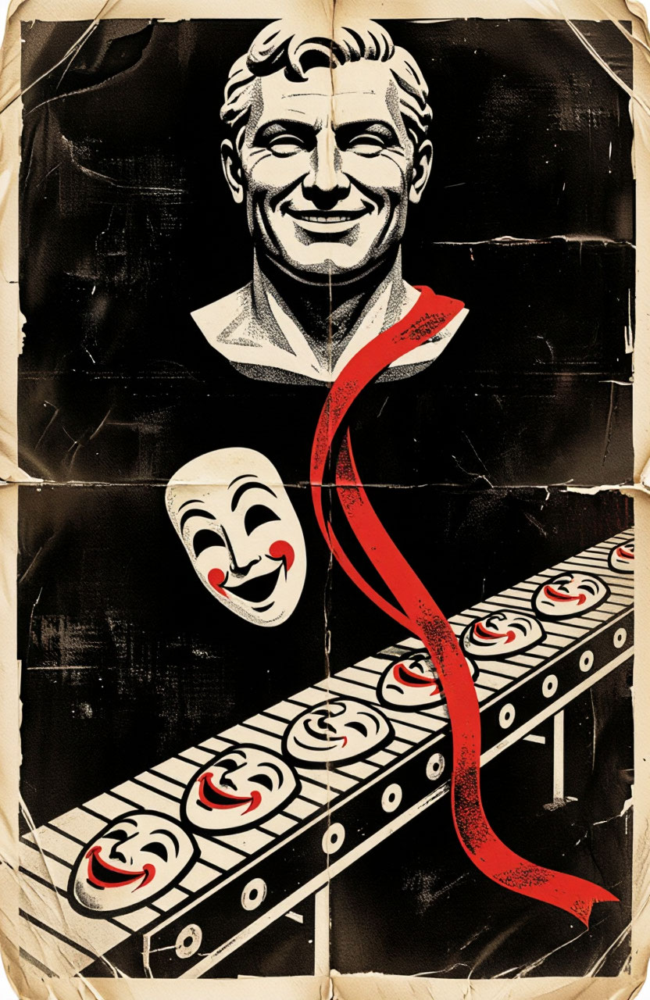
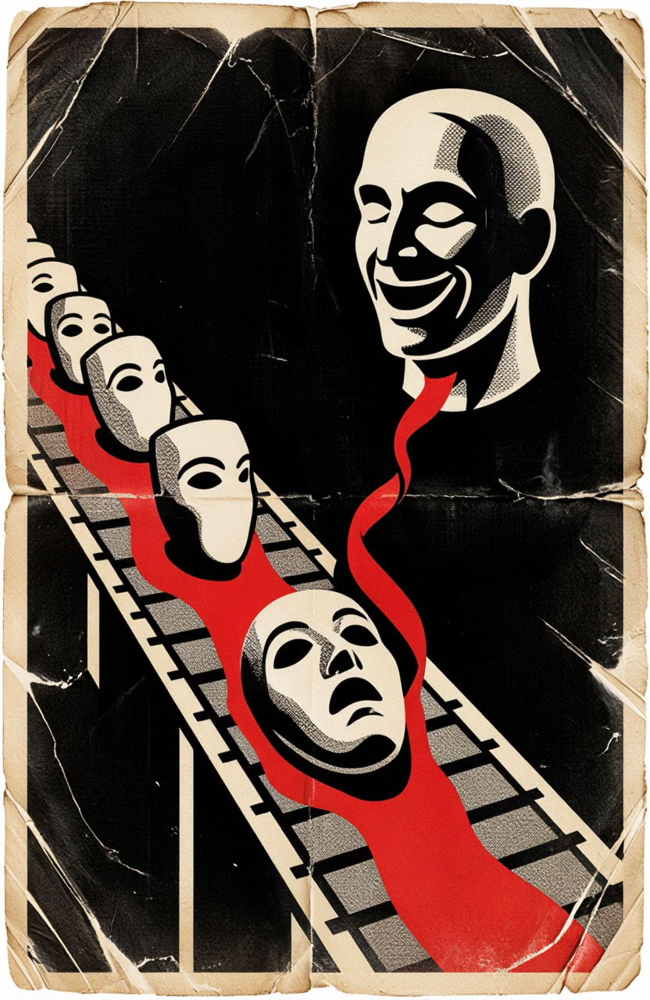

**Выбрана версия 2.** Версия 2 точнее передаёт замысел: бюст безликий, маски — пустые формы, перевёрнутая маска с открытой внутренней стороной подчёркивает отсутствие лица. Палитра и текстура ксерокса работают на тревогу, а не восхищение. Недостатки: одна маска не перевёрнута, а просто выражает страх; конвейер слишком «чистый», нет потёртостей и оборванных краёв. Правка: заменить центральную маску на перевёрнутую, добавить царапины и сгибы на ленту и фон.

**Оставшиеся недостатки:** Центральная маска не перевёрнута, а показывает испуганное лицо, что ослабляет метафору пустоты.; Конвейер и фон слишком гладкие, нет характерных потёртостей, сгибов и оборванных краёв, которые усиливают эффект ксероксного плаката.

**Версия 1:** смысл 8/10, композиция 9/10, оригинальность 7/10. Субъективная оценка VLM.

**Версия 2:** смысл 8/10, композиция 9/10, оригинальность 7/10. Субъективная оценка VLM.

#### Куратор · 01-brief
Модель: `deepseek-v4.1-flash/latest` · API: `responses`

...

**Вход:**

Замысел:
{"concept":"Фабрика популярности производит супергероя как штамп: культ не создаёт спасителя, а серийно выпускает пустые улыбки. Проклятие в том, что за героическим образом нет лица — только форма, которую продают и надевают.","metaphor":"Гипсовый улыбающийся идол-бюст — пресс-форма; конвейер штампует одинаковые карнавальные маски с его улыбкой. Одна маска перевёрнута: вместо лица — безличная пустота. Красная лента связывает идола и маски как кровеносная система культа.","focal_object":"Перевёрнутая пустая карнавальная маска на красной конвейерной ленте под монументальным гипсовым бюстом улыбающегося супергероя.","composition":"Вертикальный плакат 2:3. Верх — давящий гипсовый бюст, почти выходящий за верхний край. Низ — грубый конвейер по диагонали, красная лента вьётся от шеи бюста к ряду одинаковых масок. Одна маска в центре перевёрнута, открывая пустую внутренность. Палитра: угольно-чёрный, киноварно-красный, грязно-кремовый; высокий контраст, растровая печать, ксероксный фотомонтаж, потёртости, сгибы, оборванные края. Людей нет, текста нет.","avoid":["буквы","надписи","логотипы","водяные знаки","эмблемы известных франшиз","портретное сходство с актёрами","натуралистические раны","кровь","глянцевый современный постер","героическая реклама","прославление супергероя","мелкие детали"]}
Оцени вторую версию; изображение приложено.

**Ответ:**

```json
{
  "observed": "Вертикальный плакат в стиле ксерокс-фотомонтажа. Сверху — гипсовый бюст улыбающегося супергероя, давящий вниз. Снизу — конвейерная лента с рядом одинаковых масок. Одна маска в центре перевёрнута, показывая пустую внутренность. Красная лента связывает бюст и маски. Палитра: чёрный, красный, кремовый. Эффект потёртостей и сгибов.",
  "strengths": [
    "Успешно передаёт идею 'штампованности' и 'пустоты' через перевёрнутую маску",
    "Красная лента как 'кровеносная система культа' работает визуально и метафорически"
  ],
  "issues": [
    "Улыбка бюста слишком 'героическая' — читается как восхищение, а не критика",
    "Конвейер слишком 'чистый' — теряет эффект 'грубой фабрики' и 'эксплуатации'"
  ],
  "revision": "Сделать улыбку бюста более 'искусственной' (например, добавить трещину или искажение), а конвейер — более 'грязным' и 'давящим' (добавить следы масла, ржавчину, наклонить ленту острее)",
  "alignment": 8,
  "composition": 9,
  "originality": 7
}
```

#### Визуальный критик · 08-selection
Модель: `qwen3.6-35b-a3b` · API: `chat.completions`

**Вход:**

Сравни обе приложенные картины: сначала версия 1, потом версия 2. Выбери одну для выставки, обоснуй по видимым различиям и отметь оставшиеся недостатки. Замысел:
{"concept":"Фабрика популярности производит супергероя как штамп: культ не создаёт спасителя, а серийно выпускает пустые улыбки. Проклятие в том, что за героическим образом нет лица — только форма, которую продают и надевают.","metaphor":"Гипсовый улыбающийся идол-бюст — пресс-форма; конвейер штампует одинаковые карнавальные маски с его улыбкой. Одна маска перевёрнута: вместо лица — безличная пустота. Красная лента связывает идола и маски как кровеносная система культа.","focal_object":"Перевёрнутая пустая карнавальная маска на красной конвейерной ленте под монументальным гипсовым бюстом улыбающегося супергероя.","composition":"Вертикальный плакат 2:3. Верх — давящий гипсовый бюст, почти выходящий за верхний край. Низ — грубый конвейер по диагонали, красная лента вьётся от шеи бюста к ряду одинаковых масок. Одна маска в центре перевёрнута, открывая пустую внутренность. Палитра: угольно-чёрный, киноварно-красный, грязно-кремовый; высокий контраст, растровая печать, ксероксный фотомонтаж, потёртости, сгибы, оборванные края. Людей нет, текста нет.","avoid":["буквы","надписи","логотипы","водяные знаки","эмблемы известных франшиз","портретное сходство с актёрами","натуралистические раны","кровь","глянцевый современный постер","героическая реклама","прославление супергероя","мелкие детали"]}

**Ответ:**

```json
{
  "selected": 2,
  "reason": "Версия 2 точнее передаёт замысел: бюст безликий, маски — пустые формы, перевёрнутая маска с открытой внутренней стороной подчёркивает отсутствие лица. Палитра и текстура ксерокса работают на тревогу, а не восхищение. Недостатки: одна маска не перевёрнута, а просто выражает страх; конвейер слишком «чистый», нет потёртостей и оборванных краёв. Правка: заменить центральную маску на перевёрнутую, добавить царапины и сгибы на ленту и фон.",
  "remaining_issues": [
    "Центральная маска не перевёрнута, а показывает испуганное лицо, что ослабляет метафору пустоты.",
    "Конвейер и фон слишком гладкие, нет характерных потёртостей, сгибов и оборванных краёв, которые усиливают эффект ксероксного плаката."
  ]
}
```

In [6]:
from IPython.display import HTML, Markdown, display

for art in results:
    directory = OUTPUTS / art["id"]
    display(Markdown(f'### {art["title"]}\n\n{art["brief"]["metaphor"]}'))
    panels = []
    for version in (1, 2):
        encoded = base64.b64encode((directory / f'v{version}.png').read_bytes()).decode()
        panels.append(f'<figure style="margin:0;flex:1;min-width:240px">'
                      f'<figcaption>Версия {version}</figcaption>'
                      f'<img alt="Версия {version}" style="width:100%;max-width:416px" '
                      f'src="data:image/png;base64,{encoded}"></figure>')
    display(HTML('<div style="display:flex;gap:16px;flex-wrap:wrap">' + ''.join(panels) + '</div>'))
    display(Markdown(f'**Выбрана версия {art["selected"]}.** {art["selection"]["reason"]}'))
    display(Markdown('**Оставшиеся недостатки:** ' + '; '.join(art['selection']['remaining_issues'])))
    for version in (1, 2):
        critique = art["scores"][version - 1]
        display(Markdown(f'**Версия {version}:** смысл {critique["alignment"]}/10, '
                         f'композиция {critique["composition"]}/10, '
                         f'оригинальность {critique["originality"]}/10. '
                         'Субъективная оценка VLM.'))
    for path in sorted(directory.glob('0*.json')):
        record = load_json(path)
        display(Markdown(f'#### {record["agent"]} · {path.stem}\n'
                         f'Модель: `{record["model"]}` · API: `{record["api"]}`'))
        display(Markdown('**Вход:**\n\n' + record['input']))
        display(Markdown('**Ответ:**\n\n```json\n' + record['output'] + '\n```'))

## Дополнительная интерпретация: SD-Turbo

Открытая модель `stabilityai/sd-turbo` работает локально через Diffusers.
Ей передаётся короткий английский промпт художника для выбранного замысла.
Формат и генератор отличаются от Yandex ART, поэтому это творческое сопоставление,
а не контролируемый тест качества моделей. Веса и параметры записаны в метаданных.


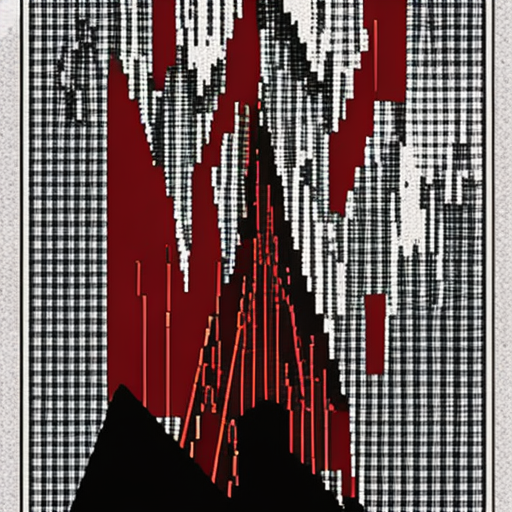

```json
{
  "model": "stabilityai/sd-turbo",
  "revision": "b261bac6fd2cf515557d5d0707481eafa0485ec2",
  "device": "mps",
  "seed": 42,
  "steps": 4,
  "guidance_scale": 0.0,
  "size": [
    512,
    512
  ],
  "prompt": "Vertical 2:3 poster: dark shield silhouette (face hidden) looms, crimson shadow transitions gradually from cone to grid over fragmented, desaturated city, high contrast, rough raster, tears/folds, no text or people",
  "prompt_tokens": 48,
  "dtype": "torch.float16",
  "torch": "2.14.1",
  "sha256": "5143b2c2f64901fceb2098282ade8aa2397bf00e7e1288b1404af7a7a869cf2d",
  "elapsed_seconds_including_load": 4.66,
  "timestamp": "2026-10-17T08:27:10.184785+00:00"
}
```

In [7]:
directory = OUTPUTS / "01-surveillance"
display(Image.open(directory / "sd-turbo.png"))
display(Markdown('```json\n' + json.dumps(load_json(directory / 'sd-turbo.json'),
                                         ensure_ascii=False, indent=2) + '\n```'))

## Выводы и ограничения

- Раздельные роли делают видимыми решения о смысле и композиции; это не доказывает
  превосходство многоагентного подхода над одним хорошим промптом.
- VLM видит изображения, однако её оценки субъективны и могут ошибаться.
